# Linear Regression

In [28]:
# get necessary dependancies
import pandas as pd
from mongo_wrangle import get_data
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statsmodels.tsa.stattools import adfuller

In [20]:
host="localhost"
port = 27017

In [21]:
# get data
df =get_data(port,host,"passengers","air_passengers")
df["month"]=pd.to_datetime(df["month"])
df=df.set_index("month")


## Time series plot

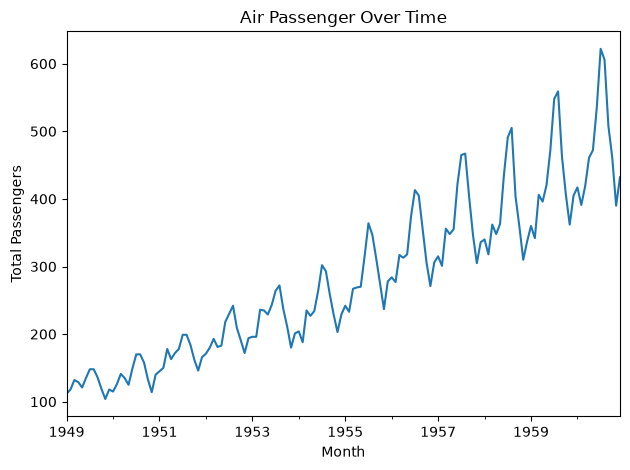

In [22]:
fig,ax =plt.subplots()
df.plot(ax=ax,y="total_passengers",legend=False)
ax.set_xlabel("Month")
ax.set_ylabel("Total Passengers")
ax.set_title("Air Passenger Over Time")
plt.tight_layout()
plt.show()

### Findings 
1. The plot is non stationary
2. The data has seasonality

In [26]:
# Make the time series stable
# log transform to stabilize variance
df["log_passengers"]=np.log(df["total_passengers"])


# differencing to remove trend and seasonality
df["log_diff"]=df["log_passengers"].diff()
df["log_diff_seasonal"]=df["log_passengers"].diff().diff(12)
df

,total_passengers,log_passengers,log_diff,log_diff_seasonal
month,,,,
1949-01-01,112,4.718499,NaN,NaN
1949-02-01,118,4.770685,0.052186,NaN
1949-03-01,132,4.882802,0.112117,NaN
1949-04-01,129,4.859812,-0.022990,NaN
1949-05-01,121,4.795791,-0.064022,NaN
...,...,...,...,...
1960-08-01,606,6.406880,-0.026060,-0.045934
1960-09-01,508,6.230481,-0.176399,0.012024
1960-10-01,461,6.133398,-0.097083,0.031830


In [30]:
# check for stationarity
def check_stationarity(series):
    result=adfuller(series.dropna())
    return result

In [ ]:
check_stationarity(df["total_passengers"])[1]

/var/folders/_r/g1b4b9xn2nn0xtb2011g11v80000gp/T/ipykernel_38779/4049249682.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result=adfuller(series.dropna())


(0.8153688792060525,
 0.991880243437641,
 13,
 130,
 {'1%': np.float64(-3.4816817173418295),
  '5%': np.float64(-2.8840418343195267),
  '10%': np.float64(-2.578770059171598)},
 np.float64(996.692930839019))

In [33]:
check_stationarity(df["log_diff_seasonal"])[1]

/var/folders/_r/g1b4b9xn2nn0xtb2011g11v80000gp/T/ipykernel_38779/4049249682.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result=adfuller(series.dropna())


0.0002485912311384052

### create lag feature

In [34]:
df =(
    df.assign(
        lag_1=lambda x:x["log_diff_seasonal"].shift(1)
    )
    .dropna()
    
)

In [35]:
df

,total_passengers,log_passengers,log_diff,log_diff_seasonal,lag_1
month,,,,,
1950-03-01,141,4.948760,0.112478,0.000361,0.039164
1950-04-01,135,4.905275,-0.043485,-0.020496,0.000361
1950-05-01,125,4.828314,-0.076961,-0.012939,-0.020496
1950-06-01,149,5.003946,0.175633,0.066148,-0.012939
1950-07-01,170,5.135798,0.131852,0.039915,0.066148
...,...,...,...,...,...
1960-08-01,606,6.406880,-0.026060,-0.045934,0.001377
1960-09-01,508,6.230481,-0.176399,0.012024,-0.045934
1960-10-01,461,6.133398,-0.097083,0.031830,0.012024
